# YOLOv8s vs RT-DETR — 2차 심화 분석 (Colab 실행용)

**하나의 노트북으로 실행합니다.** ① 오류별 검수표 ② 상대적 크기별 실패 원인 및 후보점수·IoU ③ 두 모델 Oracle 합집합 Recall ④ 원본 캐시가 있으면 GT/YOLO/RT-DETR 비교 이미지 ⑤ **별도 Validation 데이터**가 있을 때만 threshold sweep.

- 기본 CSV 분석은 GPU/재학습이 필요 없습니다.
- **실제 비교 이미지**는 원본 `external_manifest.json`, `prediction_cache_index.json`, `external_protocol.json`, 원본 사진, 예측 캐시가 있어야 가능합니다.
- **외부 테스트셋을 threshold 선택에 사용하지 않습니다.** Validation 폴더는 반드시 별도 데이터여야 합니다.
- 수치 기반 실패 유형은 모델 내부의 인과적 이유가 아니며, 그림자·노면 보수·GT 오류는 사람이 검수합니다.

**실행**: 런타임 → 모두 실행. 2번 셀에서 경로/옵션을 설정하세요.

In [ ]:
# 1. 드라이브 연결 · 필수 라이브러리
from google.colab import drive, files
drive.mount('/content/drive')
!pip -q install pandas numpy pillow matplotlib
from pathlib import Path
import os, json, subprocess, sys, shutil
import pandas as pd
from IPython.display import display, Image as IPyImage
print('Drive 연결됨')

Mounted at /content/drive
Drive 연결됨


## 2. 환경 설정

- CSV 5개를 **같은 폴더에 넣고 `CSV_DIR`에 해당 폴더 경로**를 넣으세요. 경로를 비우면(빈 문자열) 브라우저에서 ZIP 또는 CSV 여러 개를 올릴 수 있습니다.
- `EXTERNAL_RUN`은 *원래 추론 실행 결과 폴더* (`external_manifest.json` 등이 있는 폴더)이며, 모르면 비우세요. 비우면 CSV 분석까지만 실행합니다.
- `VALIDATION_RUN`은 **원본 외부 테스트와 완전히 다른 검증 데이터**가 동일 구조로 평가된 경우만 입력하세요. 기본은 비활성.
- 결과는 Drive의 새 폴더에 저장됩니다.

In [ ]:
# ===== 사용자 설정 =====
CSV_DIR = ''  # 예: '/content/drive/MyDrive/Pothole/korean_external_results/external_.../error_size_analysis_...'
OUTPUT_DIR = '/content/drive/MyDrive/pothole_followup_colab'
EXTERNAL_RUN = ''  # 예: '/content/drive/MyDrive/Pothole/korean_external_results/external_2026...'
VALIDATION_RUN = ''  # 외부 테스트와 별도인 validation 결과 폴더만!
IMAGE_ROOT = ''  # 원본 이미지가 이동했을 때만 지정
CACHE_ROOT = ''  # prediction_cache 경로가 이동했을 때만 지정

REVIEW_FOLD = 1
REVIEW_TARGET = 0.2
PER_GROUP = 12  # 오류 유형별 최대 검수 사례
EXPORT_IMAGES = True  # EXTERNAL_RUN이 있어야 실제 이미지 생성
RUN_VALIDATION_SWEEP = False  # VALIDATION_RUN이 있을 때만 True

# CSV_DIR 미입력 시 업로드 창에서 다섯 CSV 또는 CSV를 포함하는 ZIP 파일을 선택
from zipfile import ZipFile
if not CSV_DIR.strip():
    uploaded=files.upload()
    upload_dir=Path('/content/pothole_csv_input');upload_dir.mkdir(parents=True,exist_ok=True)
    for name,data in uploaded.items():
        dest=upload_dir/Path(name).name
        dest.write_bytes(data)
        if dest.suffix.lower()=='.zip':
            with ZipFile(dest) as z:
                # 경로 탈출 방지
                for m in z.infolist():
                    pp=Path(m.filename)
                    if pp.is_absolute() or '..' in pp.parts: raise ValueError('안전하지 않은 ZIP 내부 경로')
                z.extractall(upload_dir)
    # 지정된 5개 CSV가 같은 위치에 있는 디렉터리를 자동 탐색
    required={'failure_image_index.csv','fp_prediction_analysis.csv','image_comparison.csv',
              'size_recall_summary.csv','failure_reasons_by_size.csv'}
    parents=[p for p in upload_dir.rglob('*') if p.is_dir() and required.issubset({x.name for x in p.iterdir()})]
    if required.issubset({x.name for x in upload_dir.iterdir()}): parents.insert(0,upload_dir)
    if not parents: raise FileNotFoundError(f'필수 CSV 5개를 같은 폴더에서 찾지 못했습니다: {required}')
    CSV_DIR=str(parents[0])

required_files=['failure_image_index.csv','fp_prediction_analysis.csv','image_comparison.csv',
                'size_recall_summary.csv','failure_reasons_by_size.csv']
missing=[x for x in required_files if not (Path(CSV_DIR)/x).exists()]
if missing: raise FileNotFoundError(f'CSV 누락: {missing} / 폴더: {CSV_DIR}')
print('CSV_DIR:',CSV_DIR,'\nOUTPUT_DIR:',OUTPUT_DIR)
print('원본 평가 폴더 지정:',bool(EXTERNAL_RUN),'| Validation 활성화:',RUN_VALIDATION_SWEEP)

Saving fp_prediction_analysis.csv to fp_prediction_analysis.csv
Saving failure_image_index.csv to failure_image_index.csv
Saving failure_reasons_by_size.csv to failure_reasons_by_size.csv
Saving image_comparison.csv to image_comparison.csv
Saving size_recall_summary.csv to size_recall_summary.csv
CSV_DIR: /content/pothole_csv_input 
OUTPUT_DIR: /content/drive/MyDrive/pothole_followup_colab
원본 평가 폴더 지정: False | Validation 활성화: False


## 3. 1차 분석 유틸리티 내장 (추가 파일 업로드 불필요)

In [ ]:
%%writefile /content/pothole_error_size_analysis.py
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""YOLOv8s vs RT-DETR: object-level error audit & relative-size recall.

Inputs are written by korean_external_yolo_rtdetr_comparison_v3.py:
  external_manifest.json, external_protocol.json, prediction_cache_index.json,
  per_image_metrics.csv, completed.json and the prediction_cache JSON files.

No training, new inference or external-test threshold calibration occurs.
Original 7-week per-fold confidence thresholds and score-greedy IoU=0.5
matching are preserved. Diagnostic thresholds are labeled as heuristics,
never as proven causal explanations. Requires numpy, pandas, Pillow, matplotlib.
"""
from __future__ import annotations

import argparse
from collections import Counter, defaultdict
from datetime import datetime
import json
import math
import os
from pathlib import Path
import shutil
import sys

import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFont

SIZE_LABELS = ('relative_small', 'relative_medium', 'relative_large')
MATCH_IOU = 0.5
DEFAULT_NEAR_IOU = 0.1
# Only descriptive, deliberately conservative image heuristics. Not causal proof.
DEFAULT_DARK = 65.0       # gray 0..255, inside bounding box
DEFAULT_CONTRAST = 12.0   # |GT inner mean - nearby ring mean|
DEFAULT_SHARPNESS = 35.0  # variance of discrete Laplacian on 1024px-thumbnail ROI


def require(condition, explanation):
    if not condition:
        raise ValueError(explanation)


def load_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8-sig'))


def write_json(path, obj):
    Path(path).write_text(json.dumps(obj, indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')


def write_csv(path, rows, columns=None):
    df = pd.DataFrame(rows)
    if columns is not None:
        df = df.reindex(columns=columns)
    df.to_csv(path, index=False, encoding='utf-8-sig')
    return df


def valid_prediction(record):
    boxes = np.asarray(record['boxes'], dtype=np.float64).reshape(-1, 4)
    scores = np.asarray(record['scores'], dtype=np.float64).reshape(-1)
    require(len(boxes) == len(scores), '캐시에서 boxes/scores 길이가 다릅니다.')
    require(np.isfinite(boxes).all() and np.isfinite(scores).all(), '캐시에 NaN/Inf가 있습니다.')
    require(np.all((0 <= scores) & (scores <= 1)), 'Confidence가 [0,1] 범위를 벗어납니다.')
    require(np.all(boxes[:, 2:] >= boxes[:, :2]), '예측 박스 좌표가 역전되었습니다.')
    return boxes, scores


def iou_matrix(boxes, gt):
    """shape (n_pred, n_gt); degenerate predictions yield zero IoU."""
    b = np.asarray(boxes, dtype=np.float64).reshape(-1, 4)
    g = np.asarray(gt, dtype=np.float64).reshape(-1, 4)
    if not len(b) or not len(g):
        return np.zeros((len(b), len(g)), dtype=np.float64)
    wh = np.maximum(0, np.minimum(b[:, None, 2:], g[None, :, 2:]) -
                    np.maximum(b[:, None, :2], g[None, :, :2]))
    inter = wh[:, :, 0] * wh[:, :, 1]
    area_b = np.maximum(0, b[:, 2:] - b[:, :2]).prod(axis=1)
    area_g = np.maximum(0, g[:, 2:] - g[:, :2]).prod(axis=1)
    union = area_b[:, None] + area_g[None, :] - inter
    return inter / np.maximum(union, 1e-15)


def match_original(gt, boxes, scores, confidence_threshold, overlap=None):
    """Exact score-ordered greedy best-unmatched-GT rule of original v3."""
    gt = np.asarray(gt, dtype=float).reshape(-1, 4)
    boxes = np.asarray(boxes, dtype=float).reshape(-1, 4)
    scores = np.asarray(scores, dtype=float).reshape(-1)
    used = np.zeros(len(gt), dtype=bool)
    assignment = np.full(len(boxes), -1, dtype=int)
    if overlap is None:
        overlap = iou_matrix(boxes, gt)
    for j in np.argsort(-scores, kind='stable'):
        if scores[j] < confidence_threshold:
            continue
        if len(gt) and np.all(boxes[j, 2:] > boxes[j, :2]):
            candidates = overlap[j].copy()
            candidates[used] = -1
            g = int(candidates.argmax())
            if candidates[g] >= MATCH_IOU:
                used[g] = True
                assignment[j] = g
    return used, assignment


def miss_diagnosis(g, scores, overlap, threshold, near_iou):
    """Evidence of *observable* failure, not hidden network activation or causal explanation."""
    ious = overlap[:, g] if len(scores) else np.empty(0)
    high = scores >= threshold
    good = ious >= MATCH_IOU
    nearby = ious >= near_iou
    high_good = high & good
    low_good = (~high) & good
    high_near = high & nearby
    low_near = (~high) & nearby
    if high_good.any():
        cause = 'MATCHING_CONFLICT'
    elif low_good.any():
        cause = 'BELOW_THRESHOLD'
    elif high_near.any():
        cause = 'LOCALIZATION_IOU_LT_05'
    elif low_near.any():
        cause = 'LOW_SCORE_AND_LOCALIZATION'
    else:
        cause = 'NO_NEARBY_CANDIDATE'
    best = int(np.argmax(ious)) if len(ious) else -1
    geom_scores = scores[good]
    return {
        'reason': cause,
        'max_candidate_iou': float(ious[best]) if best >= 0 else None,
        'score_at_max_iou': float(scores[best]) if best >= 0 else None,
        'best_candidate_iou_at_threshold': float(ious[high].max()) if high.any() else None,
        'best_iou_ge05_score': float(geom_scores.max()) if len(geom_scores) else None,
        'n_candidates_iou_ge05': int(good.sum()),
        'n_nearby_candidates': int(nearby.sum()),
        'confidence_gap_for_good_box': (float(threshold - geom_scores.max())
                                        if len(geom_scores) else None),
    }


def fp_diagnosis(pred_index, gt, overlap, threshold, near_iou):
    ious = overlap[pred_index] if len(gt) else np.array([])
    top = float(ious.max()) if len(ious) else 0.0
    if not len(gt):
        reason = 'NEGATIVE_IMAGE_FP'
    elif top >= MATCH_IOU:
        reason = 'GT_OVERLAP_EXTRA_FP'
    elif top >= near_iou:
        reason = 'LOCALIZATION_FP'
    else:
        reason = 'BACKGROUND_FP'
    return reason, top


def box_area(box):
    return float(max(0, box[2] - box[0]) * max(0, box[3] - box[1]))


def resolve_image(row, image_root=None):
    original = Path(row['image'])
    if original.is_file():
        return original
    if image_root is not None:
        fallback = Path(image_root) / row.get('relative_image', original.name)
        if fallback.is_file():
            return fallback
    raise FileNotFoundError('원본 이미지 파일이 없습니다. Drive를 마운트하거나 --image-root를 사용하세요: ' + str(original))


def thumb_gray(path, max_side=1024):
    with Image.open(path) as src:
        gray = src.convert('L')
        w, h = gray.size
        ratio = min(1.0, max_side / max(w, h))
        if ratio < 1.0:
            gray = gray.resize((max(1, round(w*ratio)), max(1, round(h*ratio))), Image.Resampling.BILINEAR)
        result = np.asarray(gray, dtype=np.float32)
        return result, result.shape[1]/w, result.shape[0]/h


def gt_visual_features(gray, sx, sy, bbox, dark, contrast, sharpness):
    H, W = gray.shape
    x1, y1, x2, y2 = bbox
    a = max(0, min(W-1, int(math.floor(x1*sx))))
    b = max(0, min(H-1, int(math.floor(y1*sy))))
    c = max(a+1, min(W, int(math.ceil(x2*sx))))
    d = max(b+1, min(H, int(math.ceil(y2*sy))))
    roi = gray[b:d, a:c]
    mean = float(roi.mean())
    sd = float(roi.std())
    # A ring around GT; exclude ROI itself to estimate local asphalt/background appearance.
    pad_x = max(4, (c-a)//2)
    pad_y = max(4, (d-b)//2)
    l, t = max(0,a-pad_x), max(0,b-pad_y)
    r, u = min(W,c+pad_x), min(H,d+pad_y)
    surround = gray[t:u, l:r]
    keep = np.ones(surround.shape, dtype=bool)
    keep[b-t:d-t, a-l:c-l] = False
    ring_mean = float(surround[keep].mean()) if keep.any() else None
    delta = abs(mean - ring_mean) if ring_mean is not None else None
    sharp = None
    if roi.shape[0] >= 5 and roi.shape[1] >= 5:
        lap = roi[:-2,1:-1] + roi[2:,1:-1] + roi[1:-1,:-2] + roi[1:-1,2:] - 4*roi[1:-1,1:-1]
        sharp = float(np.var(lap))
    possible = []
    if mean < dark:
        possible.append('DARK_ROI')
    if delta is not None and delta < contrast:
        possible.append('LOW_LOCAL_BRIGHTNESS_DIFFERENCE')
    if sharp is not None and sharp < sharpness:
        possible.append('LOW_LAPLACIAN_VARIANCE')
    return {'gt_brightness_0_255':mean, 'gt_gray_std':sd,
            'gt_context_mean_difference':delta, 'gt_laplacian_variance':sharp,
            'visual_risk_flags':';'.join(possible),
            'dark_flag':mean < dark,
            'low_local_difference_flag':(delta < contrast) if delta is not None else None,
            'low_sharpness_flag':(sharp < sharpness) if sharp is not None else None}


def build_ground_truth(rows, image_root, q_low=0.25, q_high=0.75,
                       skip_visual_features=False, dark=DEFAULT_DARK,
                       contrast=DEFAULT_CONTRAST, sharpness=DEFAULT_SHARPNESS):
    assert 0 < q_low < q_high < 1
    identities = set()
    areas = []
    descriptors = {}
    resolved = {}
    for idx, row in enumerate(rows, 1):
        image_id = row['image_id']
        require(image_id not in identities, 'external_manifest.json에 이미지 ID 중복이 있습니다.')
        identities.add(image_id)
        w, h = int(row['width']), int(row['height'])
        require(w>0 and h>0, '원본 크기가 0입니다.')
        path = resolve_image(row, image_root)
        resolved[image_id] = str(path)
        # Always compute image pixel-derived features from the original image only.
        if not skip_visual_features and row['gt']:
            gray, sx, sy = thumb_gray(path)
        else:
            gray, sx, sy = None, None, None
        for j, box in enumerate(row['gt']):
            area = box_area(box)
            require(area > 0, f'면적이 0인 GT: {path}, index={j}')
            frac = area/(w*h)
            base = {'image_id':image_id, 'image':str(path), 'relative_image':row.get('relative_image',Path(path).name),
                    'gt_index':j, 'gt_id':f'{image_id[:16]}_g{j:03d}',
                    'gt_x1':float(box[0]), 'gt_y1':float(box[1]), 'gt_x2':float(box[2]), 'gt_y2':float(box[3]),
                    'gt_area_px2':area, 'gt_relative_area':frac,
                    'gt_width_ratio':float((box[2]-box[0])/w), 'gt_height_ratio':float((box[3]-box[1])/h),
                    'gt_center_y_ratio':float((box[1]+box[3])/(2*h)), 'coco_small':bool(area < 1024)}
            if gray is not None:
                base.update(gt_visual_features(gray,sx,sy,box,dark,contrast,sharpness))
            else:
                base.update({'gt_brightness_0_255':None,'gt_gray_std':None,
                             'gt_context_mean_difference':None,'gt_laplacian_variance':None,
                             'visual_risk_flags':'NOT_MEASURED','dark_flag':None,
                             'low_local_difference_flag':None,'low_sharpness_flag':None})
            descriptors[(image_id,j)] = base
            areas.append(frac)
        if idx % 100 == 0 or idx == len(rows):
            print(f'[GT 분석] 이미지 {idx}/{len(rows)}')
    require(bool(areas), '분석할 포트홀 GT가 없습니다.')
    lo, hi = np.quantile(areas, [q_low,q_high])
    for base in descriptors.values():
        a = base['gt_relative_area']
        base['relative_size_bin'] = ('relative_small' if a <= lo else
                                     'relative_large' if a >= hi else 'relative_medium')
    dist = Counter(d['relative_size_bin'] for d in descriptors.values())
    print('[크기 경계]', 'q25=',f'{lo:.8f}', 'q75=',f'{hi:.8f}', 'count=',dict(dist))
    if lo == hi:
        print('[경고] 분위수 경계가 동일해 일부 크기 구간이 비어 있을 수 있습니다.')
    return descriptors, resolved, {'relative_area_quantile_low':float(lo), 'relative_area_quantile_high':float(hi),
                                    'quantile_levels':[q_low,q_high], 'counts':dict(dist),
                                    'coco_small_objects':int(sum(d['coco_small'] for d in descriptors.values())),
                                    'total_gt':len(areas)}


def cache_path(cache_str, cache_root):
    p = Path(cache_str)
    if p.is_file():
        return p
    if cache_root is not None:
        alternate = Path(cache_root) / p.name
        if alternate.is_file():
            return alternate
    raise FileNotFoundError('예측 캐시를 찾을 수 없습니다. --cache-root 확인: '+str(p))


def load_cache(path, expected_model, expected_ids, candidate_floor):
    obj = load_json(path)
    require(obj['signature']['model'] == expected_model, f'캐시 모델 불일치: {path}')
    pred = obj['predictions']
    require(set(pred) == expected_ids, f'캐시 이미지 집합 불일치: {path}')
    for v in pred.values():
        _, s = valid_prediction(v)
        require(np.all(s >= candidate_floor - 1e-8), '추론 conf floor보다 낮은 캐시 점수가 있습니다.')
    return pred


def target_slug(value):
    return ('%.8g' % float(value)).replace('.','p')


def produce_plots(summary, error_counts, gt_descriptors, out_dir):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    plt.rcParams['axes.unicode_minus'] = False
    # Quantile boundaries and model-group recall; no small-COCO recall fabricated.
    fig, ax = plt.subplots(figsize=(11,5))
    labels = SIZE_LABELS
    targets = sorted(summary['target_fp_per_image'].unique())
    x = np.arange(len(labels), dtype=float)
    width = 0.8/max(1,2*len(targets))
    colors={'yolo':'#2678B8','rtdetr':'#EF8A27'}
    for k,(target,model) in enumerate((t,m) for t in targets for m in ('yolo','rtdetr')):
        segment=summary[(summary.model==model)&(summary.target_fp_per_image==target)].set_index('relative_size_bin')
        vals=[segment.loc[g,'recall_mean']*100 if g in segment.index and pd.notna(segment.loc[g,'recall_mean']) else np.nan for g in labels]
        err=[segment.loc[g,'recall_sd']*100 if g in segment.index and pd.notna(segment.loc[g,'recall_sd']) else 0 for g in labels]
        offset=(k-(2*len(targets)-1)/2)*width
        ax.bar(x+offset, vals, width, color=colors[model], alpha=0.65 if k<2 else 1.,
               label=f'{model} @ target {target}', yerr=err, capsize=2)
    ax.set_xticks(x, ['Low area (<= Q25)','Mid area (Q25-Q75)','High area (>= Q75)'])
    ax.set_ylabel('Recall (%)')
    ax.set_title('Relative-area recall (checkpoint mean ± SD; not CI)')
    ax.set_ylim(0,100)
    ax.grid(axis='y',alpha=.15)
    ax.legend(fontsize=9)
    fig.tight_layout(); fig.savefig(out_dir/'relative_size_recall.png',dpi=160);plt.close(fig)

    fig,axs=plt.subplots(1,2,figsize=(13,4.8))
    vals=np.asarray([v['gt_relative_area'] for v in gt_descriptors.values()])
    axs[0].hist(vals*100,bins=30,edgecolor='white')
    axs[0].set_xlabel('GT box area / image area (%)');axs[0].set_ylabel('GT count')
    axs[0].set_title('Relative GT area distribution')
    axs[1].hist([v['gt_area_px2'] for v in gt_descriptors.values()], bins=30,edgecolor='white')
    axs[1].axvline(1024,linestyle='--',color='gray',label='COCO small: 1024 px²')
    axs[1].set_xlabel('GT bounding-box area (pixels²)');axs[1].set_ylabel('GT count')
    axs[1].set_title('Original-pixel GT area distribution');axs[1].legend()
    fig.tight_layout();fig.savefig(out_dir/'gt_size_distribution.png',dpi=160);plt.close(fig)

    errors=error_counts[error_counts['error_kind']=='FN'].copy()
    if len(errors):
        # Average number of GT misses per checkpoint, not inflated x5 observations.
        piv=(errors.groupby(['model','reason'],as_index=False)['count'].mean())
        ax=piv.pivot(index='reason',columns='model',values='count').fillna(0).plot(kind='barh',figsize=(11,5.5))
        ax.set_title('Failure diagnostics by model (mean count per fold/target group)')
        ax.set_xlabel('Mean number (descriptive only)');ax.set_ylabel('Diagnostic reason')
        ax.figure.tight_layout();ax.figure.savefig(out_dir/'fn_reason_counts.png',dpi=160)
        plt.close(ax.figure)


def fit_image(image, max_side=800):
    img=image.copy().convert('RGB')
    w,h=img.size
    ratio=min(1.0,max_side/max(w,h))
    if ratio<1:
        img=img.resize((max(1,round(w*ratio)),max(1,round(h*ratio))),Image.Resampling.BILINEAR)
    return img, img.width/w, img.height/h


def paint_box(draw, bbox, scale_x,scale_y,color,label=None,dashed=False,width=3):
    x1,y1,x2,y2=bbox
    rect=[int(x1*scale_x),int(y1*scale_y),int(x2*scale_x),int(y2*scale_y)]
    if dashed:
        # Pillow draw.rectangle does not expose dashed outlines.
        x0,y0,x3,y3=rect
        for i in range(x0,x3+1,14):
            draw.line([(i,y0),(min(i+8,x3),y0)],fill=color,width=width)
            draw.line([(i,y3),(min(i+8,x3),y3)],fill=color,width=width)
        for i in range(y0,y3+1,14):
            draw.line([(x0,i),(x0,min(i+8,y3))],fill=color,width=width)
            draw.line([(x3,i),(x3,min(i+8,y3))],fill=color,width=width)
    else:
        draw.rectangle(rect,outline=color,width=width)
    if label:
        lx,ly=max(0,rect[0]),max(0,rect[1]-15)
        draw.rectangle((lx,ly,lx+min(150,8*len(label)+7),ly+14),fill=(0,0,0))
        draw.text((lx+2,ly+1),label,fill=color)


def render_triptych(image_path, gt, y_pred, r_pred, y_threshold, r_threshold, fold, target, outfile):
    with Image.open(image_path) as source:
        original, sx, sy=fit_image(source)
    bases=[original.copy(),original.copy(),original.copy()]
    d=[ImageDraw.Draw(img) for img in bases]
    green=(40,235,70); orange=(245,165,10); red=(255,60,55)
    for g,bbox in enumerate(gt):
        paint_box(d[0],bbox,sx,sy,green,f'GT{g}')
    summaries=[]
    for m,(pred,t) in enumerate(((y_pred,y_threshold),(r_pred,r_threshold)),start=1):
        b,s=valid_prediction(pred)
        gt_array=np.asarray(gt,dtype=float).reshape(-1,4)
        hit,assigned=match_original(gt_array,b,s,t)
        for j in np.flatnonzero(s>=t):
            label=f'{"TP" if assigned[j]>=0 else "FP"} {s[j]:.2f}'
            paint_box(d[m],b[j],sx,sy,green if assigned[j]>=0 else red,label)
        for g in np.flatnonzero(~hit):
            paint_box(d[m],gt[g],sx,sy,orange,f'FN{g}',dashed=True)
        summaries.append((int(hit.sum()),int((s>=t).sum()-hit.sum()),int(len(gt)-hit.sum())))
    pad=41; gap=8
    canvas=Image.new('RGB',(3*original.width+2*gap,original.height+pad),(255,255,255))
    headings=[f'GROUND TRUTH | objects={len(gt)}',
              f'YOLO | TP/FP/FN={summaries[0]} | thr={y_threshold:.3f}',
              f'RTDETR | TP/FP/FN={summaries[1]} | thr={r_threshold:.3f}']
    draw=ImageDraw.Draw(canvas)
    for k,img in enumerate(bases):
        x=k*(original.width+gap)
        canvas.paste(img,(x,pad))
        draw.text((x+8,8),headings[k],fill=(0,0,0))
    outfile.parent.mkdir(parents=True,exist_ok=True)
    canvas.save(outfile,quality=88,optimize=True)


def draw_case_files(requests, out_dir, run_info, img_rows, resolved,
                    cache_files, candidate_floor, case_limit):
    """Write one annotated composite per distinct image/fold/target; linked to reason folders."""
    selected=defaultdict(list)
    for (fold,target,tag), image_ids in sorted(requests.items()):
        ordered=sorted(image_ids)
        if case_limit > 0:
            ordered=ordered[:case_limit]
        for image_id in ordered:
            selected[(fold,target,image_id)].append(tag)
    output=[]
    ids=set(img_rows)
    by_fold=defaultdict(list)
    for key,tags in selected.items():
        by_fold[key[0]].append((key,tags))
    for fold, jobs in sorted(by_fold.items()):
        pred={model:load_cache(cache_files[(fold,model)],model,ids,candidate_floor)
              for model in ('yolo','rtdetr')}
        for n,((f,target,image_id),tags) in enumerate(jobs,1):
            meta=run_info[(f,target)]
            stem=f'{image_id[:18]}.jpg'
            canonical=out_dir/'annotated'/f'fold_{f}'/f'target_{target_slug(target)}'/stem
            render_triptych(resolved[image_id],img_rows[image_id]['gt'],pred['yolo'][image_id],pred['rtdetr'][image_id],
                            meta['yolo'],meta['rtdetr'],f,target,canonical)
            for tag in sorted(tags):
                case_dir=out_dir/'cases'/f'fold_{f}'/f'target_{target_slug(target)}'/tag
                case_dir.mkdir(parents=True,exist_ok=True)
                dest=case_dir/stem
                try:
                    os.link(canonical,dest)
                except OSError:
                    shutil.copy2(canonical,dest)
                output.append({'fold':f,'target_fp_per_image':target,'image_id':image_id,
                               'category_or_reason':tag,'original_image':resolved[image_id],
                               'annotated_path':str(canonical),'case_path':str(dest)})
            if n%30==0 or n==len(jobs):
                print(f'[예시 이미지 저장] fold {f}: {n}/{len(jobs)}')
    return write_csv(out_dir/'case_export_index.csv',output,
                     ['fold','target_fp_per_image','image_id','category_or_reason','original_image','annotated_path','case_path'])


def analyze(run_dir, output_dir=None, image_root=None, cache_root=None,
            case_folds=(1,), case_targets=None, max_cases_per_folder=20,
            export_images=True, skip_visual_features=False,
            near_iou=DEFAULT_NEAR_IOU, dark=DEFAULT_DARK,
            contrast=DEFAULT_CONTRAST, sharpness=DEFAULT_SHARPNESS,
            case_reason_filter=None):
    run_dir=Path(run_dir).expanduser().resolve()
    require(run_dir.is_dir(), f'기존 평가 결과 폴더가 없습니다: {run_dir}')
    for name in ('completed.json','external_manifest.json','prediction_cache_index.json',
                 'external_protocol.json','per_image_metrics.csv'):
        require((run_dir/name).is_file(),f'필수 파일이 없습니다: {run_dir/name}\n원래 외부 평가가 완료된 폴더를 지정하세요.')
    completed=load_json(run_dir/'completed.json')
    require(completed.get('status')=='complete','기존 외부 평가 completed.json이 complete가 아닙니다.')
    manifest=load_json(run_dir/'external_manifest.json')
    protocol=load_json(run_dir/'external_protocol.json')
    index=load_json(run_dir/'prediction_cache_index.json')
    original=pd.read_csv(run_dir/'per_image_metrics.csv',encoding='utf-8-sig',dtype={'image_id':str})
    expected={'image_id','fold','model','target_fp_per_image','tp','fp','fn','gt'}
    require(expected<=set(original.columns), '기존 per_image_metrics.csv에 필요한 열이 없습니다.')
    require(len(manifest)==int(completed['unique_images']), '완료 파일과 manifest 이미지 수가 다릅니다.')
    img_rows={r['image_id']:r for r in manifest}
    require(len(img_rows)==len(manifest),'manifest에 중복 image_id가 있습니다.')
    expected_ids=set(img_rows)
    cache_index={(int(p['fold']),p['model']):cache_path(p['cache'],cache_root) for p in index}
    require(len(cache_index)==len(index),'prediction_cache_index.json에 중복 fold/model이 있습니다.')
    ops={(int(o['fold']),o['model'],float(o['target_fp_per_image'])):float(o['threshold'])
         for o in protocol['operating_points']}
    folds=sorted({k[0] for k in ops})
    targets=sorted({k[2] for k in ops})
    for fold in folds:
        for model in ('yolo','rtdetr'):
            require((fold,model) in cache_index, f'fold{fold}/{model} 캐시 누락')
            for target in targets:
                require((fold,model,target) in ops, f'fold{fold}/{model}/target{target} threshold 누락')
    if case_targets is None:
        case_targets=tuple(targets)
    require(all(int(x) in folds for x in case_folds),f'case_folds에 없는 Fold 포함: {case_folds}')
    require(all(float(x) in targets for x in case_targets),f'case_targets에 없는 FP 목표 포함: {case_targets}')
    require(0 <= near_iou < MATCH_IOU, 'near_iou는 0 이상, 0.5 미만이어야 합니다.')
    if case_reason_filter is not None:
        case_reason_filter = set(case_reason_filter)
        require(bool(case_reason_filter), 'case_reason_filter가 비었습니다.')
    if output_dir is None:
        output_dir=run_dir/('error_size_analysis_'+datetime.now().strftime('%Y%m%d_%H%M%S'))
    output_dir=Path(output_dir).expanduser().resolve()
    require(not output_dir.exists(),f'출력 폴더가 이미 있습니다. 다른 --output-dir을 지정하세요: {output_dir}')
    output_dir.mkdir(parents=True)
    print('[입력]',run_dir,'| [출력]',output_dir)
    candidate_floor=float(protocol['inference']['conf'])
    descriptors,resolved,size_info=build_ground_truth(manifest,image_root,
        skip_visual_features=skip_visual_features, dark=dark,contrast=contrast,sharpness=sharpness)
    write_csv(output_dir/'gt_object_features.csv',list(descriptors.values()))
    write_json(output_dir/'size_bins.json',size_info)

    # Verify existing v3 per-image counts for every same operating point, not just totals.
    baseline={(int(r.fold),r.model,float(r.target_fp_per_image),r.image_id):
              (int(r.tp),int(r.fp),int(r.fn),int(r.gt)) for r in original.itertuples(index=False)}
    require(len(baseline)==len(original),'기존 per_image_metrics.csv에 중복 행이 있습니다.')
    require(len(baseline)==len(manifest)*2*len(folds)*len(targets),
            '기존 per_image_metrics.csv의 이미지/Fold/목표 조합이 완전하지 않습니다.')

    gt_out=[]; image_out=[]; fp_out=[]; size_out=[]; disagree=[]; failure_index=[]
    export_requests=defaultdict(set)
    threshold_lookup={}
    for fold in folds:
        pred={m:load_cache(cache_index[(fold,m)],m,expected_ids,candidate_floor)
              for m in ('yolo','rtdetr')}
        for target in targets:
            thresholds={m:ops[(fold,m,target)] for m in ('yolo','rtdetr')}
            threshold_lookup[(fold,target)]=thresholds
            count_sizes={(m,s):[0,0] for m in ('yolo','rtdetr') for s in SIZE_LABELS}
            count_disagree={s:Counter() for s in SIZE_LABELS}
            for num,row in enumerate(manifest,1):
                image_id=row['image_id']
                gt=np.asarray(row['gt'],dtype=float).reshape(-1,4)
                info={}
                for model in ('yolo','rtdetr'):
                    boxes,scores=valid_prediction(pred[model][image_id])
                    overlap=iou_matrix(boxes,gt)
                    used,assignment=match_original(gt,boxes,scores,thresholds[model],overlap)
                    tp=int(used.sum()); fp=int((scores>=thresholds[model]).sum()-tp); fn=len(gt)-tp
                    key=(fold,model,target,image_id)
                    require(key in baseline, f'기존 per_image_metrics.csv에 행이 없습니다: {key}')
                    require((tp,fp,fn,len(gt))==baseline[key],
                        f'기존 평가 결과와 불일치 {key}: 신규={(tp,fp,fn,len(gt))}, 기존={baseline[key]}. '
                        '원본 캐시와 manifest가 같은 평가 실행에서 생성됐는지 확인하세요.')
                    info[model]={'used':used,'assignment':assignment,'boxes':boxes,'scores':scores,
                                 'overlap':overlap,'tp':tp,'fp':fp,'fn':fn}
                    for j in np.flatnonzero((scores>=thresholds[model]) & (assignment<0)):
                        reason,top=fp_diagnosis(j,gt,overlap,thresholds[model],near_iou)
                        fp_out.append({'fold':fold,'target_fp_per_image':target,'model':model,
                                       'image_id':image_id,'image':resolved[image_id],
                                       'prediction_index':int(j),'fp_reason':reason,
                                       'confidence':float(scores[j]),'threshold':thresholds[model],
                                       'max_gt_iou':top, 'x1':float(boxes[j,0]),'y1':float(boxes[j,1]),
                                       'x2':float(boxes[j,2]),'y2':float(boxes[j,3]),
                                       'prediction_area_px2':box_area(boxes[j])})
                        if (export_images and fold in case_folds and target in case_targets and
                                (case_reason_filter is None or reason in case_reason_filter)):
                            export_requests[(fold,target,f'FP_{model.upper()}__{reason}')].add(image_id)
                y,r=info['yolo'],info['rtdetr']
                counts=Counter()
                for j in range(len(gt)):
                    desc=descriptors[(image_id,j)]
                    success={m:bool(info[m]['used'][j]) for m in ('yolo','rtdetr')}
                    outcome=('both_detected' if success['yolo'] and success['rtdetr'] else
                             'yolo_only' if success['yolo'] else
                             'rtdetr_only' if success['rtdetr'] else 'both_missed')
                    counts[outcome]+=1
                    size=desc['relative_size_bin']
                    count_disagree[size][outcome]+=1
                    record={'fold':fold,'target_fp_per_image':target,**desc,
                            'joint_outcome':outcome}
                    for m in ('yolo','rtdetr'):
                        count_sizes[(m,size)][1]+=1
                        if success[m]:
                            count_sizes[(m,size)][0]+=1
                            pidx=int(np.flatnonzero(info[m]['assignment']==j)[0])
                            record.update({f'{m}_tp':1,f'{m}_fn':0,f'{m}_reason':'DETECTED',
                                           f'{m}_confidence':float(info[m]['scores'][pidx]),
                                           f'{m}_matched_iou':float(info[m]['overlap'][pidx,j]),
                                           f'{m}_max_candidate_iou':float(info[m]['overlap'][:,j].max()),
                                           f'{m}_score_at_max_iou':None,
                                           f'{m}_best_candidate_iou_at_threshold':None,
                                           f'{m}_best_iou_ge05_score':None,
                                           f'{m}_n_candidates_iou_ge05':None,
                                           f'{m}_n_nearby_candidates':None,
                                           f'{m}_confidence_gap_for_good_box':None,
                                           f'{m}_threshold':thresholds[m]})
                        else:
                            fail=miss_diagnosis(j,info[m]['scores'],info[m]['overlap'],thresholds[m],near_iou)
                            record.update({f'{m}_tp':0,f'{m}_fn':1,f'{m}_reason':fail.pop('reason'),
                                           f'{m}_confidence':None,f'{m}_matched_iou':None,
                                           f'{m}_threshold':thresholds[m]})
                            record.update({f'{m}_{k}':v for k,v in fail.items()})
                            failure_index.append({'fold':fold,'target_fp_per_image':target,
                                                  'model':m,'image_id':image_id,'image':resolved[image_id],
                                                  'gt_index':j,'gt_id':desc['gt_id'],
                                                  'failure_reason':record[f'{m}_reason'],
                                                  'relative_size_bin':size,
                                                  'gt_relative_area':desc['gt_relative_area'],
                                                  'visual_risk_flags':desc['visual_risk_flags'],
                                                  'confidence_threshold':thresholds[m],
                                                  'candidate_floor':candidate_floor,
                                                  'max_candidate_iou':record[f'{m}_max_candidate_iou'],
                                                  'best_iou_ge05_score':record[f'{m}_best_iou_ge05_score']})
                    gt_out.append(record)
                image_out.append({'fold':fold,'target_fp_per_image':target,'image_id':image_id,
                                  'image':resolved[image_id],'gt_count':len(gt),
                                  'both_detected_gt':counts['both_detected'],
                                  'yolo_only_gt':counts['yolo_only'],
                                  'rtdetr_only_gt':counts['rtdetr_only'],
                                  'both_missed_gt':counts['both_missed'],
                                  'yolo_tp':y['tp'],'yolo_fp':y['fp'],'yolo_fn':y['fn'],
                                  'rtdetr_tp':r['tp'],'rtdetr_fp':r['fp'],'rtdetr_fn':r['fn'],
                                  'image_category':('negative_gt' if not len(gt) else
                                                    'both_complete' if counts['both_detected']==len(gt) else
                                                    'yolo_only_complete' if counts['yolo_only']==len(gt) else
                                                    'rtdetr_only_complete' if counts['rtdetr_only']==len(gt) else
                                                    'both_failed_complete' if counts['both_missed']==len(gt) else
                                                    'mixed')})
                if (export_images and fold in case_folds and target in case_targets
                        and case_reason_filter is None):
                    for outcome, n_gt in counts.items():
                        if n_gt:
                            export_requests[(fold,target,'GT_'+outcome.upper())].add(image_id)
                    if y['fp']:
                        export_requests[(fold,target,'FP_YOLO')].add(image_id)
                    if r['fp']:
                        export_requests[(fold,target,'FP_RTDETR')].add(image_id)
            for (model,size),(tp,n_gt) in count_sizes.items():
                size_out.append({'fold':fold,'target_fp_per_image':target,'model':model,
                                 'relative_size_bin':size,'tp':tp,'fn':n_gt-tp,'gt':n_gt,
                                 'recall':(tp/n_gt if n_gt else np.nan)})
            for size,cnts in count_disagree.items():
                disagree.append({'fold':fold,'target_fp_per_image':target,'relative_size_bin':size,
                                 'gt':sum(cnts.values()),
                                 **{k:cnts[k] for k in ('both_detected','yolo_only','rtdetr_only','both_missed')}})
            print(f'[객체 일치 검사] fold={fold} target={target}: {len(manifest)} images OK')
        del pred

    gt_df=write_csv(output_dir/'gt_object_analysis.csv',gt_out)
    img_df=write_csv(output_dir/'image_comparison.csv',image_out)
    fp_df=write_csv(output_dir/'fp_prediction_analysis.csv',fp_out)
    size_df=write_csv(output_dir/'size_recall_by_checkpoint.csv',size_out)
    write_csv(output_dir/'model_disagreement_by_size.csv',disagree)
    failures=write_csv(output_dir/'failure_image_index.csv',failure_index)
    # Physical/environmental causes cannot be inferred reliably from prediction IoU/score.
    # Provide explicit independent human annotations instead of auto-labeling shadows, water, etc.
    human_review_rows = [
        {'error_kind':'FN','fold':r['fold'],'target_fp_per_image':r['target_fp_per_image'],
         'model':r['model'],'image_id':r['image_id'],'image':r['image'],
         'gt_index':r['gt_index'],'prediction_index':None,'diagnostic_reason':r['failure_reason'],
         'relative_size_bin':r['relative_size_bin'],'visual_risk_flags':r['visual_risk_flags']}
        for r in failure_index
    ]
    human_review_rows += [
        {'error_kind':'FP','fold':r['fold'],'target_fp_per_image':r['target_fp_per_image'],
         'model':r['model'],'image_id':r['image_id'],'image':r['image'],
         'gt_index':None,'prediction_index':r['prediction_index'],'diagnostic_reason':r['fp_reason'],
         'relative_size_bin':None,'visual_risk_flags':None}
        for r in fp_out
    ]
    human_review = pd.DataFrame(human_review_rows,columns=['error_kind','fold','target_fp_per_image',
        'model','image_id','image','gt_index','prediction_index','diagnostic_reason',
        'relative_size_bin','visual_risk_flags'])
    human_review['manual_primary_cause'] = ''
    human_review['manual_secondary_cause'] = ''
    human_review['manual_gt_is_valid'] = ''
    human_review['manual_environment'] = ''
    human_review['manual_reviewer'] = ''
    human_review['manual_notes'] = ''
    human_review.to_csv(output_dir/'human_review_template.csv',index=False,encoding='utf-8-sig')

    size_summary=(size_df.groupby(['target_fp_per_image','model','relative_size_bin'],sort=True)
                  .agg(checkpoints=('recall','size'), unique_gt=('gt','first'),
                       recall_mean=('recall','mean'), recall_sd=('recall',lambda s:s.std(ddof=1)),
                       tp_mean=('tp','mean')).reset_index())
    size_summary.to_csv(output_dir/'size_recall_summary.csv',index=False,encoding='utf-8-sig')

    # Full error category counts per fold/target; columns explicitly preserve the unit of observation.
    fn_counts=(failures.groupby(['fold','target_fp_per_image','model','failure_reason']).size()
               .rename('count').reset_index().rename(columns={'failure_reason':'reason'}))
    fn_counts['error_kind']='FN'
    if len(fp_df):
        fp_counts=(fp_df.groupby(['fold','target_fp_per_image','model','fp_reason']).size()
                   .rename('count').reset_index().rename(columns={'fp_reason':'reason'}))
        fp_counts['error_kind']='FP'
        reason_df=pd.concat([fn_counts,fp_counts],ignore_index=True)
    else:
        reason_df=fn_counts.copy()
    # A diagnostic reason absent in one fold means zero, not missing-at-random.
    # Add the missing fold rows before computing means and SDs.
    full_reason_rows=[]
    for (target,model,kind,reason), sub in reason_df.groupby(
            ['target_fp_per_image','model','error_kind','reason']):
        existing={int(row.fold):int(row.count) for row in sub.itertuples(index=False)}
        for fold in folds:
            full_reason_rows.append({'fold':fold,'target_fp_per_image':target,
                                     'model':model,'error_kind':kind,'reason':reason,
                                     'count':existing.get(fold,0)})
    reason_df=pd.DataFrame(full_reason_rows,columns=['fold','target_fp_per_image','model',
                                                      'error_kind','reason','count'])
    reason_df.to_csv(output_dir/'error_reason_counts_by_checkpoint.csv',index=False,encoding='utf-8-sig')
    if len(reason_df):
        reason_summary=(reason_df.groupby(['target_fp_per_image','model','error_kind','reason'])
                        .agg(checkpoints=('count','size'),count_mean=('count','mean'),
                             count_sd=('count',lambda s:s.std(ddof=1)),
                             count_sum_checkpoint_observations=('count','sum')).reset_index())
    else:
        reason_summary=pd.DataFrame(columns=['target_fp_per_image','model','error_kind',
                                              'reason','checkpoints','count_mean','count_sd',
                                              'count_sum_checkpoint_observations'])
    reason_summary.to_csv(output_dir/'error_reason_summary.csv',index=False,encoding='utf-8-sig')
    if len(failures):
        by_size=(failures.groupby(['fold','target_fp_per_image','model',
                                   'relative_size_bin','failure_reason']).size()
                 .rename('fn_count').reset_index())
        by_size=by_size.merge(size_df[['fold','target_fp_per_image','model','relative_size_bin','gt']],
                              on=['fold','target_fp_per_image','model','relative_size_bin'],
                              how='left',validate='many_to_one')
        by_size['fn_per_size_gt']=by_size['fn_count']/by_size['gt']
    else:
        by_size=pd.DataFrame(columns=['fold','target_fp_per_image','model',
                                      'relative_size_bin','failure_reason','fn_count','gt',
                                      'fn_per_size_gt'])
    by_size.to_csv(output_dir/'failure_reasons_by_size.csv',index=False,encoding='utf-8-sig')
    # Split recall by candidate visual risk flags. Correlation, NOT causation.
    cond=[]
    for model in ('yolo','rtdetr'):
        for source_col,indicator in [('dark_flag','DARK_ROI'),
                                    ('low_local_difference_flag','LOW_LOCAL_BRIGHTNESS_DIFFERENCE'),
                                    ('low_sharpness_flag','LOW_LAPLACIAN_VARIANCE')]:
            if source_col not in gt_df or gt_df[source_col].isna().all():
                continue
            for (fold,target,flag), sub in gt_df[gt_df[source_col].notna()].groupby(
                        ['fold','target_fp_per_image',source_col]):
                n=len(sub); k=int(sub[f'{model}_tp'].sum())
                cond.append({'fold':fold,'target_fp_per_image':target,'model':model,
                             'visual_indicator':indicator,'flag':bool(flag),
                             'gt':n,'tp':k,'fn':n-k,'recall':k/n})
    write_csv(output_dir/'recall_by_visual_indicator.csv',cond,
              ['fold','target_fp_per_image','model','visual_indicator','flag','gt','tp','fn','recall'])
    produce_plots(size_summary,reason_df,descriptors,output_dir)

    if export_images:
        for row in failure_index:
            if (row['fold'] in case_folds and row['target_fp_per_image'] in case_targets and
                    (case_reason_filter is None or row['failure_reason'] in case_reason_filter)):
                tag=f'FN_{row["model"].upper()}__{row["failure_reason"]}'
                export_requests[(row['fold'],row['target_fp_per_image'],tag)].add(row['image_id'])
        draw_case_files(export_requests,output_dir,threshold_lookup,img_rows,resolved,cache_index,
                        candidate_floor,max_cases_per_folder)

    meta={'original_run':str(run_dir),'images':len(manifest),'unique_gt':len(descriptors),
          'folds':folds,'targets':targets,'match_iou':MATCH_IOU,
          'nearby_iou_heuristic':near_iou,'prediction_conf_floor':candidate_floor,
          'source_thresholds':[{"fold":f,"target":t,**threshold_lookup[(f,t)]} for f in folds for t in targets],
          'size_bins':size_info,'visual_heuristics':{'dark_gt_mean_below':dark,
              'gt_vs_context_mean_difference_below':contrast,
              'laplacian_variance_below':sharpness,'downsample_max_side_px':1024},
          'visual_features_skipped':skip_visual_features,
          'case_folds':list(case_folds),'case_targets':list(case_targets),
          'case_max_per_folder':max_cases_per_folder,'images_exported':bool(export_images),
          'case_reason_filter':sorted(case_reason_filter) if case_reason_filter else None,
          'manual_cause_options':['SHADOW','ROAD_REPAIR_PATCH','WATER_OR_REFLECTION','LOW_LIGHT',
             'MOTION_BLUR','LOW_CONTRAST','SMALL_OR_DISTANT','OCCLUSION',
             'ANNOTATION_ISSUE','OTHER','UNKNOWN'],
          'limitations':[
              'Failure reasons are observable prediction/IoU/score conditions, not proven causes.',
              'Candidates suppressed by model preprocessing/NMS or below original conf floor are unobservable.',
              'TIDE-inspired custom diagnostics: not the official TIDE six-error API.',
              'Relative area bins are dataset-specific quantiles, not COCO Small/Medium/Large.',
              'Same external images are reused by all folds; checkpoint SD is not a confidence interval.',
              'Visual-risk flags are predefined descriptive heuristics, not model explanations.',
              'Original validation thresholds are frozen; external data are never used to retune them.']}
    write_json(output_dir/'analysis_metadata.json',meta)
    readme='''# YOLOv8s / RT-DETR: 객체별 탐지 오류 및 크기별 Recall 분석\n\n'''
    readme+='**기존 실험:** '+str(run_dir)+'\n\n'
    readme+='''## 중요\n\n- 두 모델은 같은 이미지와 GT에서 비교되며, Fold/Validation FP 목표/Confidence는 원본 기록을 그대로 사용합니다.\n- `GT_*` 폴더는 **이미지에 해당 결과의 GT가 하나 이상 있는 경우**를 뜻합니다. 객체가 2~3개인 이미지는 여러 폴더에 동시에 포함될 수 있습니다. 배타적인 **이미지 전체 성공**은 `image_comparison.csv`의 `image_category`를 확인하세요.\n- `FN_*`은 모델별로 놓친 GT의 이유별 이미지입니다. 한 이미지에 여러 GT가 있으면 여러 이유 폴더에 존재할 수 있습니다.\n- `FP_*` 이미지에도 진짜 포트홀이 존재할 수 있습니다. FP는 *예측 박스* 단위로 계산합니다.\n- 케이스 이미지는 왼쪽 GT / 가운데 YOLO / 오른쪽 RT-DETR. 초록색 TP, 빨간색 FP, 주황색 점선 FN.\n- `case_export_index.csv`는 실제 저장된 예시 이미지만 기록합니다. **전체 실패 이미지/객체 목록은 `failure_image_index.csv`에 전부 포함**됩니다. 더 많이 저장하려면 `--max-cases-per-folder 0`을 사용하세요. 특정 오류만 저장하려면 `--case-reasons BELOW_THRESHOLD NO_NEARBY_CANDIDATE` 옵션을 사용하세요. 용량에 주의하세요.\n\n## FN 이유 코드 (모델 내부의 인과적 이유가 아님)\n\n- `BELOW_THRESHOLD`: IoU >= 0.5 후보가 있지만 고정 threshold 미만.\n- `MATCHING_CONFLICT`: threshold 이상 & IoU >= 0.5 후보가 존재하나 다른 GT에 점수 우선 매칭되어 이 GT가 FN.\n- `LOCALIZATION_IOU_LT_05`: threshold 이상의 가까운 후보가 있지만 IoU < 0.5.\n- `LOW_SCORE_AND_LOCALIZATION`: 가까운 후보가 있으나 confidence도 부족하고 IoU도 < 0.5.\n- `NO_NEARBY_CANDIDATE`: **캐시에 남은 후보 중** IoU >= near_iou 후보 없음. (모델 내부에 활성화가 없었다는 뜻은 아님)\n\n## FP 이유 코드\n\n- `NEGATIVE_IMAGE_FP`: GT가 0개인 이미지에서 나온 예측.\n- `GT_OVERLAP_EXTRA_FP`: GT와 IoU >= 0.5이나 그 GT가 이미 다른 예측에 매칭되어 FP로 계산된 추가 박스.\n- `LOCALIZATION_FP`: 최대 IoU는 nearby IoU 이상 0.5 미만.\n- `BACKGROUND_FP`: GT와 최대 IoU가 nearby IoU 미만. 실제 어떤 물체인지 자동 확정 불가.\n\n## 시각적 보조 지표\n\n`gt_object_features.csv`는 밝기, 주변과의 평균 밝기 차이, Laplacian variance를 저장합니다.\n`DARK_ROI`, `LOW_LOCAL_BRIGHTNESS_DIFFERENCE`, `LOW_LAPLACIAN_VARIANCE`는 임의의 사전 정의 **관찰 위험 표시**이고 실패의 원인을 증명하지 않습니다.\n후속 검수자는 이미지의 그림자, 포장 보수 흔적, 노면 반사, GT 오류를 직접 확인하고 검수 열을 추가하세요.\n\n## Relative-size Recall\n\n원본 bbox 픽셀 면적 / 이미지 픽셀 면적의 분위수(25%, 75%)로 Smallest / Middle / Largest 그룹을 만듭니다.\n모든 GT를 한 번만 세어 경계를 고정하고, Fold/target별로 같은 GT 그룹을 반복 평가합니다.\nCOCO Small(`area < 1024 px²`)과 **완전히 다른 지표**입니다. 각 그룹 Recall = 해당 그룹 TP / 해당 그룹 GT.\n같은 외부 이미지가 5개 Fold에 반복되므로 Fold SD는 신뢰구간이 아닙니다.\n\n## 주요 출력\n\n- `gt_object_analysis.csv`: GT마다 YOLO/RT-DETR TP/FN, 판단 이유, score/IoU, 크기, 시각 지표\n- `failure_image_index.csv`: 놓친 GT 전체 + 원본 이미지 경로 + 원인 후보\n- `fp_prediction_analysis.csv`: FP 박스마다 score/IoU/FP 유형\n- `human_review_template.csv`: FN/FP를 실제 영상으로 확인 후 원인(SHADOW, ROAD_REPAIR_PATCH, WATER_OR_REFLECTION, LOW_LIGHT, MOTION_BLUR, LOW_CONTRAST, SMALL_OR_DISTANT, OCCLUSION, ANNOTATION_ISSUE, OTHER, UNKNOWN)을 수동 입력할 검수표\n- `image_comparison.csv`: 이미지별 결과 비교, 배타적 이미지 카테고리\n- `gt_object_features.csv`: 모델과 독립적인 GT 크기/시각 특징\n- `size_recall_by_checkpoint.csv`, `size_recall_summary.csv`: 그룹별 Recall 및 Fold 평균·SD\n- `model_disagreement_by_size.csv`: 크기별 두 모델의 TP/FN 불일치\n- `error_reason_counts_by_checkpoint.csv`, `error_reason_summary.csv`: 오류 유형별 빈도(해당 Fold에 0건이어도 0으로 집계)\n- `failure_reasons_by_size.csv`: 크기 그룹별 탐지 실패 이유와 해당 크기 GT 대비 비율\n- `recall_by_visual_indicator.csv`: 시각 지표 조건별 Recall (인과 추론 금지)\n- `cases/`: 유형별 사례 이미지, `annotated/`: 원본 합성 그림, `case_export_index.csv`: 저장 인덱스\n\n'''
    (output_dir/'README_분석설명.md').write_text(readme,encoding='utf-8')
    print('\n[완료]', output_dir)
    print('[검증] 원본 CSV의 TP/FP/FN과 전 이미지, 전 Fold, 전 목표 일치')
    print('[GT]',len(descriptors),'| [COCO Small]',size_info['coco_small_objects'])
    return output_dir


def self_test():
    # Test the matching method, including score order, FN and FP diagnostics.
    gt=np.array([[10,10,30,30]],dtype=float)
    boxes=np.array([[10,10,30,30],[10,10,30,30],[15,15,35,35]],dtype=float)
    scores=np.array([.95,.70,.90])
    ov=iou_matrix(boxes,gt)
    hit,assigned=match_original(gt,boxes,scores,.5,ov)
    assert hit.tolist()==[True] and assigned.tolist()==[0,-1,-1]
    assert fp_diagnosis(1,gt,ov,.5,.1)[0]=='GT_OVERLAP_EXTRA_FP'
    hit,assigned=match_original(gt,boxes,scores,.96,ov)
    assert not hit.any()
    assert miss_diagnosis(0,scores,ov,.96,.1)['reason']=='BELOW_THRESHOLD'
    assert miss_diagnosis(0,np.array([.8]),iou_matrix([[15,15,35,35]],gt),.5,.1)['reason']=='LOCALIZATION_IOU_LT_05'
    assert miss_diagnosis(0,np.array([]),np.zeros((0,1)),.5,.1)['reason']=='NO_NEARBY_CANDIDATE'
    assert fp_diagnosis(0,np.empty((0,4)),np.empty((1,0)),.5,.1)[0]=='NEGATIVE_IMAGE_FP'
    print('PASS: 기본 match / duplicate FP / threshold FN / localization FN / missing candidate / negative FP')


def main():
    ap=argparse.ArgumentParser(description='기존 외부 평가 캐시로 탐지 성공·실패 및 Relative-size Recall 분석')
    ap.add_argument('--run-dir',type=Path,help='기존 평가의 external_... 결과 폴더')
    ap.add_argument('--output-dir',type=Path,help='분석 출력 신규 폴더(기본: run-dir/error_size_analysis_날짜)')
    ap.add_argument('--image-root',type=Path,help='원본 이미지가 옮겨진 경우 상대경로가 시작되는 폴더')
    ap.add_argument('--cache-root',type=Path,help='캐시 파일 경로가 이동된 경우 prediction_cache 폴더')
    ap.add_argument('--case-folds',type=int,nargs='+',default=[1],help='이미지 저장 Fold (집계는 모든 Fold)')
    ap.add_argument('--case-targets',type=float,nargs='+',default=None,help='이미지 저장 FP targets (집계는 모두)')
    ap.add_argument('--case-reasons',nargs='+',default=None,
                    help='이미지 파일은 지정한 진단 사유만 추출(모든 CSV 집계는 유지). 예: BELOW_THRESHOLD NO_NEARBY_CANDIDATE')
    ap.add_argument('--max-cases-per-folder',type=int,default=20,
                    help='카테고리/이유별 저장 최대 이미지 수; 0이면 전체(용량 큼)')
    ap.add_argument('--no-export-images',action='store_true',help='CSV/그래프만 생성')
    ap.add_argument('--skip-visual-features',action='store_true',help='원본 이미지의 밝기/블러 계산 생략')
    ap.add_argument('--near-iou',type=float,default=DEFAULT_NEAR_IOU,
                    help='"nearby" 진단용 IoU 경계(기본 0.1; 정답 매칭 0.5는 변경 안 됨)')
    ap.add_argument('--dark-threshold',type=float,default=DEFAULT_DARK)
    ap.add_argument('--contrast-threshold',type=float,default=DEFAULT_CONTRAST)
    ap.add_argument('--sharpness-threshold',type=float,default=DEFAULT_SHARPNESS)
    ap.add_argument('--self-test',action='store_true',help='합성 유닛 테스트 후 종료')
    args=ap.parse_args()
    if args.self_test:
        self_test()
        return
    if args.run_dir is None:
        ap.error('기존 외부 평가 결과 폴더 --run-dir 필수')
    analyze(args.run_dir,args.output_dir,args.image_root,args.cache_root,
            case_folds=tuple(args.case_folds),case_targets=args.case_targets,
            max_cases_per_folder=args.max_cases_per_folder,
            export_images=not args.no_export_images,
            skip_visual_features=args.skip_visual_features,
            near_iou=args.near_iou,dark=args.dark_threshold,
            contrast=args.contrast_threshold,sharpness=args.sharpness_threshold,
            case_reason_filter=args.case_reasons)


if __name__=='__main__':
    main()


Writing /content/pothole_error_size_analysis.py


## 4. 2차 심화 분석 코드 내장

In [ ]:
%%writefile /content/pothole_followup_analysis.py
#!/usr/bin/env python3
"""Follow-up diagnostics for the existing YOLOv8s / RT-DETR external experiment.
External test: descriptive analysis only. Validation: threshold calibration only.
"""
import argparse, json, sys
from pathlib import Path
import numpy as np
import pandas as pd

MODELS=('yolo','rtdetr')
SIZES=('relative_small','relative_medium','relative_large')
def csv(path):
    return pd.read_csv(path,encoding='utf-8-sig',dtype={'image_id':str})
def save(df,p):
    df.to_csv(p,index=False,encoding='utf-8-sig')
def req(x,msg):
    if not x: raise ValueError(msg)
def read_manifest(p):
    rows=json.loads(Path(p).read_text(encoding='utf-8'))
    req(isinstance(rows,list),'manifest must be a list')
    return rows

def analyze_csv(inp,out,fold=1,target=.2,per_group=12):
    out.mkdir(parents=True,exist_ok=True)
    f=csv(inp/'failure_image_index.csv')
    fp=csv(inp/'fp_prediction_analysis.csv')
    im=csv(inp/'image_comparison.csv')
    sr=csv(inp/'size_recall_summary.csv')
    fr=csv(inp/'failure_reasons_by_size.csv')
    req(set(MODELS)<=set(f.model.unique()),'Both model records required')
    # Size-specific FN: aggregate counts first, divide by unique GT count, then average folds.
    reason=fr.groupby(['target_fp_per_image','model','relative_size_bin','failure_reason'],as_index=False).agg(
        fn_sum=('fn_count','sum'))
    totals=fr.groupby(['fold','target_fp_per_image','model','relative_size_bin'],as_index=False).agg(
        fn=('fn_count','sum'),gt=('gt','first'))
    mean=totals.groupby(['target_fp_per_image','model','relative_size_bin'],as_index=False).agg(
        mean_fn=('fn','mean'),mean_gt=('gt','mean'))
    mean['fn_rate']=mean.mean_fn/mean.mean_gt
    save(mean,out/'size_miss_rates.csv')
    reason=reason.merge(mean,on=['target_fp_per_image','model','relative_size_bin'])
    reason['mean_fn_count']=reason.fn_sum/len(totals.fold.unique())
    reason['share_of_FN']=reason.mean_fn_count/reason.mean_fn.replace(0,np.nan)
    reason['share_of_GT']=reason.mean_fn_count/reason.mean_gt.replace(0,np.nan)
    save(reason,out/'size_reason_breakdown.csv')
    # Candidate scores are available only for missed GT. Do not call this an all-object confidence distribution.
    ff=f.copy()
    ff['score_gap']=ff.confidence_threshold-ff.best_iou_ge05_score
    summary=ff.groupby(['target_fp_per_image','model','relative_size_bin'],as_index=False).agg(
        n_missed=('gt_id','size'),
        candidate_iou_median=('max_candidate_iou','median'),
        candidate_iou_q25=('max_candidate_iou',lambda x:x.quantile(.25)),
        candidate_iou_q75=('max_candidate_iou',lambda x:x.quantile(.75)),
        good_candidate_score_median=('best_iou_ge05_score','median'),
        good_candidate_score_q25=('best_iou_ge05_score',lambda x:x.quantile(.25)),
        good_candidate_score_q75=('best_iou_ge05_score',lambda x:x.quantile(.75)),
        score_gap_median=('score_gap','median'),
        n_with_good_candidate=('best_iou_ge05_score','count'))
    summary['good_candidate_fraction_among_FN']=summary.n_with_good_candidate/summary.n_missed
    save(summary,out/'fn_candidate_distribution_by_size.csv')
    # Score distribution for actual FPs.
    fp_summary=fp.groupby(['target_fp_per_image','model','fp_reason'],as_index=False).agg(
        count=('confidence','size'),median_confidence=('confidence','median'),
        q25_confidence=('confidence',lambda x:x.quantile(.25)),
        q75_confidence=('confidence',lambda x:x.quantile(.75)),
        median_max_gt_iou=('max_gt_iou','median'))
    save(fp_summary,out/'fp_confidence_summary.csv')
    # Upper bound: an oracle knows which GT each model detected. NOT deployable ensemble.
    oracle=im.groupby(['fold','target_fp_per_image'],as_index=False)[
        ['gt_count','both_detected_gt','yolo_only_gt','rtdetr_only_gt','both_missed_gt']].sum()
    req((oracle.gt_count==oracle[['both_detected_gt','yolo_only_gt','rtdetr_only_gt','both_missed_gt']].sum(axis=1)).all(),
        'GT accounting mismatch')
    oracle['oracle_union_recall']=(oracle.both_detected_gt+oracle.yolo_only_gt+oracle.rtdetr_only_gt)/oracle.gt_count
    oracle['yolo_recall']=(oracle.both_detected_gt+oracle.yolo_only_gt)/oracle.gt_count
    oracle['rtdetr_recall']=(oracle.both_detected_gt+oracle.rtdetr_only_gt)/oracle.gt_count
    save(oracle,out/'oracle_union_by_fold.csv')
    save(oracle.groupby('target_fp_per_image',as_index=False)[
        ['oracle_union_recall','yolo_recall','rtdetr_recall']].mean(),out/'oracle_union_summary.csv')
    # Fixed and reproducible review sampling, no test-based threshold choice.
    f=f[(f.fold==fold)&np.isclose(f.target_fp_per_image,target)].copy()
    fp=fp[(fp.fold==fold)&np.isclose(fp.target_fp_per_image,target)].copy()
    selected=[]
    groups=[
        ('FN_BELOW_THRESHOLD',f[f.failure_reason=='BELOW_THRESHOLD']),
        ('FN_NO_NEARBY',f[f.failure_reason=='NO_NEARBY_CANDIDATE']),
        ('FN_LOCALIZATION',f[f.failure_reason.isin(['LOCALIZATION_IOU_LT_05','LOW_SCORE_AND_LOCALIZATION'])]),
        ('FN_SMALL',f[f.relative_size_bin=='relative_small']),
        ('FP_BACKGROUND',fp[fp.fp_reason=='BACKGROUND_FP']),
        ('FP_OTHER',fp[fp.fp_reason!='BACKGROUND_FP'])]
    for name,frame in groups:
        # Stable hash sort avoids selection based on visually appealing examples.
        frame=frame.copy()
        frame['_key']=(frame.image_id.astype(str)+'_'+frame.model.astype(str)+'_'+
                      (frame.gt_index if 'gt_index' in frame else frame.prediction_index).astype(str))
        frame=frame.sort_values('_key').head(per_group)
        for r in frame.to_dict('records'):
            selected.append({'review_group':name,'fold':int(r['fold']),
                             'target_fp_per_image':float(r['target_fp_per_image']),
                             'model':r['model'],'image_id':r['image_id'],'image':r['image'],
                             'gt_index':r.get('gt_index',np.nan),'prediction_index':r.get('prediction_index',np.nan),
                             'diagnostic_reason':r.get('failure_reason',r.get('fp_reason','')),
                             'relative_size_bin':r.get('relative_size_bin',''),
                             'max_candidate_iou':r.get('max_candidate_iou',np.nan),
                             'candidate_score':r.get('best_iou_ge05_score',np.nan),
                             'visual_risk_flags':r.get('visual_risk_flags',''),
                             'manual_primary_cause':'','manual_secondary_cause':'',
                             'gt_annotation_valid':'','reviewer':'','review_notes':''})
    review=pd.DataFrame(selected).drop_duplicates(['model','image_id','gt_index','prediction_index','diagnostic_reason'])
    save(review,out/'review_queue.csv')
    (out/'review_labels.json').write_text(json.dumps({
        'manual_primary_cause':['shadow','road_patch','low_contrast','occlusion','wet_reflection',
                                'motion_blur','small_visual_extent','annotation_error','other','uncertain'],
        'gt_annotation_valid':['yes','no','uncertain'],
        'note':'These labels require visual inspection; they are not automatically inferred.'},
        ensure_ascii=False,indent=2),encoding='utf-8')
    # Select image IDs; actual triptych generation requires the original cache/manifest.
    ids=review[['image_id','image']].drop_duplicates()
    save(ids,out/'review_images_to_export.csv')
    print('CSV analysis finished:',out,'review cases:',len(review))

def import_eval_module(path):
    import importlib.util
    spec=importlib.util.spec_from_file_location('pothole_previous',path)
    mod=importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)
    return mod

def export_review_images(run_dir,review_path,out,helper_path,cache_root=None,image_root=None):
    """Reconstruct triptychs with exact original thresholds and prediction caches."""
    mod=import_eval_module(helper_path)
    manifest=read_manifest(run_dir/'external_manifest.json')
    by_id={r['image_id']:r for r in manifest}
    protocol=json.loads((run_dir/'external_protocol.json').read_text(encoding='utf-8'))
    idx=json.loads((run_dir/'prediction_cache_index.json').read_text(encoding='utf-8'))
    cache={(int(x['fold']),x['model']):mod.cache_path(x['cache'],cache_root) for x in idx}
    thresholds={(int(x['fold']),x['model'],float(x['target_fp_per_image'])):float(x['threshold'])
                for x in protocol['operating_points']}
    review=csv(review_path)
    out.mkdir(parents=True,exist_ok=True)
    ids=set(by_id)
    resolved={k:str(mod.resolve_image(r,image_root)) for k,r in by_id.items()}
    for (fold,target),frame in review.groupby(['fold','target_fp_per_image']):
        pred={m:mod.load_cache(cache[(int(fold),m)],m,ids,float(protocol['inference']['conf'])) for m in MODELS}
        for image_id in frame.image_id.unique():
            r=by_id[image_id]
            image=resolved[image_id]
            dst=out/f'fold{int(fold)}_target{str(target).replace(".","p")}_{image_id[:18]}.jpg'
            mod.render_triptych(image,r['gt'],pred['yolo'][image_id],pred['rtdetr'][image_id],
                thresholds[(int(fold),'yolo',float(target))],
                thresholds[(int(fold),'rtdetr',float(target))],int(fold),float(target),dst)
        print('Exported review images for',fold,target)

def sweep_validation(validation_dir,out,helper_path,thresholds=None,cache_root=None):
    """Only on a *separate* validation run. Never pass the external test folder."""
    mod=import_eval_module(helper_path)
    validation_dir=Path(validation_dir)
    proto=json.loads((validation_dir/'external_protocol.json').read_text(encoding='utf-8'))
    manifest=read_manifest(validation_dir/'external_manifest.json')
    idx=json.loads((validation_dir/'prediction_cache_index.json').read_text(encoding='utf-8'))
    floor=float(proto['inference']['conf'])
    thresholds=np.linspace(max(.01,floor),.99,60) if thresholds is None else thresholds
    rows=[]
    ids=set(r['image_id'] for r in manifest)
    for item in idx:
        fold=int(item['fold']); model=item['model']
        pred=mod.load_cache(mod.cache_path(item['cache'],cache_root),model,ids,floor)
        for t in thresholds:
            TP=FP=GT=0
            for r in manifest:
                boxes,scores=mod.valid_prediction(pred[r['image_id']])
                gt=np.asarray(r['gt'],dtype=float).reshape(-1,4)
                hit,_=mod.match_original(gt,boxes,scores,float(t))
                TP+=int(hit.sum());FP+=int((scores>=t).sum()-hit.sum());GT+=len(gt)
            rows.append({'fold':fold,'model':model,'threshold':float(t),
                         'recall':TP/GT if GT else np.nan,'fp_per_image':FP/len(manifest),
                         'tp':TP,'fp':FP,'gt':GT})
    df=pd.DataFrame(rows)
    out.mkdir(parents=True,exist_ok=True)
    save(df,out/'validation_threshold_sweep.csv')
    # Selection uses validation only; feasible thresholds satisfy the FP budget.
    picks=[]
    for (fold,model),g in df.groupby(['fold','model']):
        for budget in (.2,.5):
            valid=g[g.fp_per_image<=budget].sort_values(['recall','threshold'],ascending=[False,False])
            if len(valid):
                best=valid.iloc[0]
                picks.append({'fold':fold,'model':model,'fp_budget':budget,
                              'validation_threshold':best.threshold,'validation_recall':best.recall,
                              'validation_fp_per_image':best.fp_per_image})
            else:
                picks.append({'fold':fold,'model':model,'fp_budget':budget,
                              'validation_threshold':np.nan,'validation_recall':np.nan,
                              'validation_fp_per_image':np.nan})
    save(pd.DataFrame(picks),out/'validation_selected_thresholds.csv')
    print('Validation sweep finished. External test has NOT been used to choose thresholds.')

def main():
    p=argparse.ArgumentParser()
    p.add_argument('--csv-dir',type=Path,required=True)
    p.add_argument('--out',type=Path,required=True)
    p.add_argument('--fold',type=int,default=1)
    p.add_argument('--target',type=float,default=.2)
    p.add_argument('--per-group',type=int,default=12)
    p.add_argument('--external-run',type=Path)
    p.add_argument('--validation-run',type=Path)
    p.add_argument('--helper',type=Path,default=Path(__file__).with_name('pothole_error_size_analysis.py'))
    p.add_argument('--cache-root',type=Path)
    p.add_argument('--image-root',type=Path)
    a=p.parse_args()
    analyze_csv(a.csv_dir,a.out,a.fold,a.target,a.per_group)
    if a.external_run:
        export_review_images(a.external_run,a.out/'review_queue.csv',a.out/'review_triptychs',
                             a.helper,a.cache_root,a.image_root)
    if a.validation_run:
        req(not a.external_run or a.validation_run.resolve()!=a.external_run.resolve(),
            'Validation run must differ from external test run.')
        sweep_validation(a.validation_run,a.out,a.helper,cache_root=a.cache_root)
if __name__=='__main__': main()


Writing /content/pothole_followup_analysis.py


## 5. CSV 통계 분석 + 이미지 검수 목록 생성

In [ ]:
out=Path(OUTPUT_DIR);out.mkdir(parents=True,exist_ok=True)
cmd=[sys.executable,'/content/pothole_followup_analysis.py',
     '--csv-dir',CSV_DIR,'--out',str(out),'--fold',str(REVIEW_FOLD),
     '--target',str(REVIEW_TARGET),'--per-group',str(PER_GROUP),
     '--helper','/content/pothole_error_size_analysis.py']
if EXPORT_IMAGES and EXTERNAL_RUN:
    cmd += ['--external-run', EXTERNAL_RUN]
    if IMAGE_ROOT: cmd += ['--image-root',IMAGE_ROOT]
    if CACHE_ROOT: cmd += ['--cache-root',CACHE_ROOT]
if RUN_VALIDATION_SWEEP:
    if not VALIDATION_RUN: raise ValueError('RUN_VALIDATION_SWEEP=True이면 VALIDATION_RUN을 지정하세요.')
    if EXTERNAL_RUN and Path(VALIDATION_RUN).resolve()==Path(EXTERNAL_RUN).resolve():
        raise ValueError('Validation과 외부 테스트는 서로 다른 폴더여야 합니다.')
    cmd += ['--validation-run',VALIDATION_RUN]
result=subprocess.run(cmd,text=True,capture_output=True)
print(result.stdout)
if result.returncode:
    print(result.stderr[-8000:]);raise RuntimeError('2차 분석 실패: 경로 및 캐시 파일을 확인하세요.')
print('결과 저장 완료:',out)

CSV analysis finished: /content/drive/MyDrive/pothole_followup_colab review cases: 68

결과 저장 완료: /content/drive/MyDrive/pothole_followup_colab


## 6. 결과표와 그래프 바로 보기

=== 크기별 미탐률 ===


,target_fp_per_image,model,relative_size_bin,mean_fn,mean_gt,fn_rate
0,0.2,rtdetr,relative_large,76.6,201.0,0.381095
3,0.2,yolo,relative_large,105.0,201.0,0.522388
1,0.2,rtdetr,relative_medium,189.6,401.0,0.472818
4,0.2,yolo,relative_medium,252.4,401.0,0.629426
2,0.2,rtdetr,relative_small,113.4,201.0,0.564179
5,0.2,yolo,relative_small,145.2,201.0,0.722388
6,0.5,rtdetr,relative_large,57.8,201.0,0.287562
9,0.5,yolo,relative_large,81.4,201.0,0.404975
7,0.5,rtdetr,relative_medium,138.6,401.0,0.345636
10,0.5,yolo,relative_medium,202.4,401.0,0.504738


=== 크기별 FN 후보점수 / IoU ===


,target_fp_per_image,model,relative_size_bin,n_missed,candidate_iou_median,candidate_iou_q25,candidate_iou_q75,good_candidate_score_median,good_candidate_score_q25,good_candidate_score_q75,score_gap_median,n_with_good_candidate,good_candidate_fraction_among_FN
0,0.2,rtdetr,relative_large,383,0.805613,0.720091,0.868410,0.362296,0.153118,0.567285,0.361056,344,0.898172
1,0.2,rtdetr,relative_medium,948,0.752171,0.642916,0.831539,0.358525,0.154787,0.584718,0.371838,819,0.863924
2,0.2,rtdetr,relative_small,567,0.719338,0.595691,0.801297,0.342281,0.150554,0.569320,0.392166,489,0.862434
3,0.2,yolo,relative_large,525,0.741696,0.584406,0.831702,0.204980,0.032236,0.531968,0.479540,419,0.798095
4,0.2,yolo,relative_medium,1262,0.698997,0.504702,0.787287,0.189789,0.024156,0.524331,0.485680,946,0.749604
5,0.2,yolo,relative_small,726,0.666236,0.539393,0.746747,0.220950,0.036588,0.534910,0.455074,575,0.792011
6,0.5,rtdetr,relative_large,289,0.801228,0.704350,0.858482,0.262146,0.097283,0.394973,0.288045,250,0.865052
7,0.5,rtdetr,relative_medium,693,0.730180,0.591961,0.809986,0.233461,0.105631,0.370978,0.300401,564,0.813853
8,0.5,rtdetr,relative_small,429,0.686918,0.566769,0.791461,0.234536,0.108254,0.369543,0.300624,351,0.818182
9,0.5,yolo,relative_large,407,0.708831,0.478171,0.810285,0.091234,0.013017,0.249573,0.401204,301,0.739558


=== 실패 유형 ===


,target_fp_per_image,model,relative_size_bin,failure_reason,fn_sum,mean_fn,mean_gt,fn_rate,mean_fn_count,share_of_FN,share_of_GT
0,0.2,rtdetr,relative_large,BELOW_THRESHOLD,344,76.6,201.0,0.381095,68.8,0.898172,0.342289
1,0.2,rtdetr,relative_large,LOCALIZATION_IOU_LT_05,4,76.6,201.0,0.381095,0.8,0.010444,0.003980
2,0.2,rtdetr,relative_large,LOW_SCORE_AND_LOCALIZATION,28,76.6,201.0,0.381095,5.6,0.073107,0.027861
3,0.2,rtdetr,relative_large,NO_NEARBY_CANDIDATE,7,76.6,201.0,0.381095,1.4,0.018277,0.006965
4,0.2,rtdetr,relative_medium,BELOW_THRESHOLD,819,189.6,401.0,0.472818,163.8,0.863924,0.408479
5,0.2,rtdetr,relative_medium,LOCALIZATION_IOU_LT_05,8,189.6,401.0,0.472818,1.6,0.008439,0.003990
6,0.2,rtdetr,relative_medium,LOW_SCORE_AND_LOCALIZATION,81,189.6,401.0,0.472818,16.2,0.085443,0.040399
7,0.2,rtdetr,relative_medium,NO_NEARBY_CANDIDATE,40,189.6,401.0,0.472818,8.0,0.042194,0.019950
8,0.2,rtdetr,relative_small,BELOW_THRESHOLD,489,113.4,201.0,0.564179,97.8,0.862434,0.486567
9,0.2,rtdetr,relative_small,LOCALIZATION_IOU_LT_05,8,113.4,201.0,0.564179,1.6,0.014109,0.007960


=== Oracle Union Recall (실제 앙상블 아님) ===


,target_fp_per_image,oracle_union_recall,yolo_recall,rtdetr_recall
0,0.2,0.588543,0.374097,0.527273
1,0.5,0.714072,0.506102,0.648568


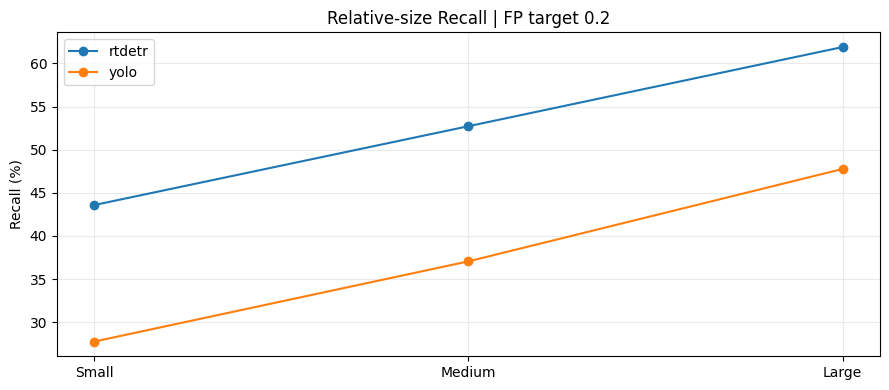

In [ ]:
import matplotlib.pyplot as plt
print('=== 크기별 미탐률 ===')
d=pd.read_csv(out/'size_miss_rates.csv');display(d.sort_values(['target_fp_per_image','relative_size_bin','model']))
print('=== 크기별 FN 후보점수 / IoU ===')
d2=pd.read_csv(out/'fn_candidate_distribution_by_size.csv');display(d2)
print('=== 실패 유형 ===')
d3=pd.read_csv(out/'size_reason_breakdown.csv');display(d3)
print('=== Oracle Union Recall (실제 앙상블 아님) ===')
uc=pd.read_csv(out/'oracle_union_summary.csv');display(uc)
fig,ax=plt.subplots(figsize=(9,4))
for model,g in d[d.target_fp_per_image==REVIEW_TARGET].groupby('model'):
    order=['relative_small','relative_medium','relative_large']
    z=g.set_index('relative_size_bin').reindex(order)
    ax.plot(['Small','Medium','Large'],100*(1-z.fn_rate),marker='o',label=model)
ax.set_ylabel('Recall (%)');ax.set_title(f'Relative-size Recall | FP target {REVIEW_TARGET}')
ax.legend();ax.grid(alpha=.25);plt.tight_layout()
fig.savefig(out/'relative_size_recall_followup.png',dpi=160);plt.show()

## 7. 실제 이미지 검수 목록 및 비교 이미지 미리보기

In [ ]:
q=pd.read_csv(out/'review_queue.csv');display(q.head(15))
imgs=sorted((out/'review_triptychs').rglob('*.jpg')) if (out/'review_triptychs').exists() else []
print('실제 비교 이미지:',len(imgs),'장')
if imgs:
    for p in imgs[:4]:
        print(p.name);display(IPyImage(filename=str(p),width=1100))
else:
    print('원본 평가 폴더/예측 캐시를 지정하지 않았거나 이미지 파일이 없습니다.')
    print('EXTERNAL_RUN에 external_manifest.json 등이 있는 원래 실행 폴더를 지정하고 다시 실행하세요.')
print('검수표:',out/'review_queue.csv')

,review_group,fold,target_fp_per_image,model,image_id,image,gt_index,prediction_index,diagnostic_reason,relative_size_bin,max_candidate_iou,candidate_score,visual_risk_flags,manual_primary_cause,manual_secondary_cause,gt_annotation_valid,reviewer,review_notes
0,FN_BELOW_THRESHOLD,1,0.2,yolo,01460b6ec4472158d37467f719dc2ed16ab7ffc65e7b4e...,/content/drive/MyDrive/pothole2/20210908_14104...,0.0,NaN,BELOW_THRESHOLD,relative_large,0.847317,0.697444,LOW_LOCAL_BRIGHTNESS_DIFFERENCE,NaN,NaN,NaN,NaN,NaN
1,FN_BELOW_THRESHOLD,1,0.2,yolo,01bb78d9defcae480fcda9e65c46400ed4a93755c1f9e1...,/content/drive/MyDrive/pothole2/20211206_16505...,0.0,NaN,BELOW_THRESHOLD,relative_large,0.510742,0.177738,LOW_LOCAL_BRIGHTNESS_DIFFERENCE,NaN,NaN,NaN,NaN,NaN
2,FN_BELOW_THRESHOLD,1,0.2,yolo,020eb0fe4cf0d1fdac6db8a2eb4baec3720e34f50d5105...,/content/drive/MyDrive/pothole2/20210909_10123...,0.0,NaN,BELOW_THRESHOLD,relative_medium,0.631326,0.551270,LOW_LOCAL_BRIGHTNESS_DIFFERENCE,NaN,NaN,NaN,NaN,NaN
3,FN_BELOW_THRESHOLD,1,0.2,yolo,0384944613326d09f998528f62d1bae4c6c0b9aebbb5fc...,/content/drive/MyDrive/pothole2/20211216_17082...,0.0,NaN,BELOW_THRESHOLD,relative_medium,0.524227,0.005794,LOW_LOCAL_BRIGHTNESS_DIFFERENCE;LOW_LAPLACIAN_...,NaN,NaN,NaN,NaN,NaN
4,FN_BELOW_THRESHOLD,1,0.2,yolo,039c7208344ef911a462e7f3fb4e91802e8065d4fc9c48...,/content/drive/MyDrive/pothole2/20210904_15190...,0.0,NaN,BELOW_THRESHOLD,relative_small,0.650405,0.173822,NaN,NaN,NaN,NaN,NaN,NaN
5,FN_BELOW_THRESHOLD,1,0.2,yolo,042f2076416faebb111ebedbc24e1a2703a4282c70fde1...,/content/drive/MyDrive/pothole2/20210911_12040...,0.0,NaN,BELOW_THRESHOLD,relative_medium,0.811709,0.732236,LOW_LOCAL_BRIGHTNESS_DIFFERENCE,NaN,NaN,NaN,NaN,NaN
6,FN_BELOW_THRESHOLD,1,0.2,yolo,04b8a37c1a9c1980b81ff5b75632fef7cc07bd59b3cc77...,/content/drive/MyDrive/pothole2/20211206_15461...,0.0,NaN,BELOW_THRESHOLD,relative_small,0.735990,0.080599,LOW_LOCAL_BRIGHTNESS_DIFFERENCE,NaN,NaN,NaN,NaN,NaN
7,FN_BELOW_THRESHOLD,1,0.2,yolo,04f6fdf08e6affff5d01108308f3b302ea83fc26e75518...,/content/drive/MyDrive/pothole2/20210910_11443...,0.0,NaN,BELOW_THRESHOLD,relative_large,0.866544,0.600945,LOW_LOCAL_BRIGHTNESS_DIFFERENCE,NaN,NaN,NaN,NaN,NaN
8,FN_BELOW_THRESHOLD,1,0.2,rtdetr,058f4bf9afcb053d8d9fa292f1a7981efaa51d0f992d0b...,/content/drive/MyDrive/pothole2/20210906_16384...,0.0,NaN,BELOW_THRESHOLD,relative_large,0.893470,0.239640,LOW_LOCAL_BRIGHTNESS_DIFFERENCE,NaN,NaN,NaN,NaN,NaN
9,FN_BELOW_THRESHOLD,1,0.2,yolo,058f4bf9afcb053d8d9fa292f1a7981efaa51d0f992d0b...,/content/drive/MyDrive/pothole2/20210906_16384...,0.0,NaN,BELOW_THRESHOLD,relative_large,0.793928,0.142810,LOW_LOCAL_BRIGHTNESS_DIFFERENCE,NaN,NaN,NaN,NaN,NaN


실제 비교 이미지: 0 장
원본 평가 폴더/예측 캐시를 지정하지 않았거나 이미지 파일이 없습니다.
EXTERNAL_RUN에 external_manifest.json 등이 있는 원래 실행 폴더를 지정하고 다시 실행하세요.
검수표: /content/drive/MyDrive/pothole_followup_colab/review_queue.csv


## 8. 결과 파일 압축 (선택)

압축파일을 Drive에 저장합니다. 이미지가 많은 경우 ZIP 용량이 커질 수 있습니다.

In [ ]:
import zipfile
zip_path=out.parent/'pothole_followup_results.zip'
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED,compresslevel=5) as z:
    for p in out.rglob('*'):
        if p.is_file():z.write(p,arcname=str(p.relative_to(out.parent)))
print('ZIP 저장:',zip_path,'용량(MB):',round(zip_path.stat().st_size/1e6,2))
# 로컬에 받으려면 아래 주석을 해제하세요.
# files.download(str(zip_path))

### 해석 시 주의
- **COCO Small Recall과 Relative Small Recall은 다릅니다.** 이번 `relative_small`은 데이터셋의 상대 크기 하위 25%입니다.
- `fn_candidate_distribution_by_size.csv`의 Confidence/IoU는 **놓친 GT의 후보값**만 요약합니다.
- `oracle_union_recall`은 GT를 아는 이상적 성능 상한이고 배포 가능한 앙상블 결과가 아닙니다.
- Threshold sweep은 **별도 Validation 세트가 있을 때만** 실행합니다. 외부 테스트에서 threshold를 최적화하면 안 됩니다.
- 추출된 JPG만으로 오류 원인을 자동 확정하지 않습니다. `review_queue.csv`의 `manual_primary_cause` 등을 직접 작성하세요.
